# LunarLander: Reinforcement Learning with PPO

This project trains an agent to land a spacecraft in the LunarLander-v3 environment using Proximal Policy Optimization (PPO).

I compare different reward strategies, evaluate trained models using episode rewards and landing conditions, and record videos of the selected model.

**Tools:** Python, Gymnasium, Stable-Baselines3, PyTorch, Matplotlib.

## 1. Environment Setup

Install the libraries required for the simulation, reinforcement-learning experiments and result visualization.

Run this cell when setting up a fresh Colab runtime.

In [ ]:
%%bash
python -m venv .venv && source .venv/bin/activate
pip install swig
pip install "gymnasium[box2d]" stable-baselines3 moviepy matplotlib
python -c "import gymnasium, stable_baselines3, Box2D; print(gymnasium.__version__, stable_baselines3.__version__)"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 103.0 MB/s eta 0:00:00
1.3.0 2.9.0


Unable to symlink '/usr/bin/python3' to '/content/.venv/bin/python3'
Error: Command '['/content/.venv/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.
I0000 00:00:1792158999.434669    5098 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792159001.557593    5098 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
<frozen imp

## 2. Environment Sanity Check

Before training an agent, test that the LunarLander environment runs correctly and returns observations, rewards and episode termination signals.

This test uses random actions and is only intended to verify the environment.

In [ ]:
import gymnasium as gym

env = gym.make("LunarLander-v3", render_mode="human")
obs, info = env.reset(seed=0)
for t in range(500):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    if t % 20 == 0:
        print(t, obs.round(2), round(reward, 2))
    if terminated or truncated:
        obs, info = env.reset()
env.close()

0 [ 0.01  1.39  0.57 -0.55 -0.01 -0.09  0.    0.  ] -0.21
20 [ 0.13  1.06  0.58 -0.89 -0.15 -0.12  0.    0.  ] -0.39
40 [ 0.24  0.56  0.64 -1.32 -0.26 -0.12  0.    0.  ] 0.41
60 [-0.02  1.43 -0.74  0.29  0.02  0.16  0.    0.  ] -0.46
80 [-0.17  1.45 -0.78 -0.15  0.22  0.16  0.    0.  ] -0.25
100 [-0.34  1.32 -0.89 -0.49  0.54  0.36  0.    0.  ] -2.22
120 [-0.55  1.06 -1.19 -0.72  0.8   0.26  0.    0.  ] -0.82
140 [-0.81  0.65 -1.51 -1.08  1.09  0.27  0.    0.  ] -3.33
160 [ 0.06  1.32  0.7  -0.56 -0.06 -0.13  0.    0.  ] -1.73
180 [ 0.2   0.99  0.76 -0.9  -0.17 -0.11  0.    0.  ] 0.62
200 [ 0.36  0.49  0.84 -1.31 -0.26 -0.23  0.    0.  ] 1.2
220 [-0.    1.43 -0.12  0.31  0.    0.03  0.    0.  ] -0.9
240 [-0.02  1.49 -0.1  -0.1   0.   -0.02  0.    0.  ] -0.81
260 [-0.04  1.35 -0.12 -0.34  0.    0.08  0.    0.  ] 3.47
280 [-0.07  1.12 -0.15 -0.69  0.04  0.09  0.    0.  ] -1.54
300 [-0.1   0.77 -0.16 -0.96  0.15  0.02  0.    0.  ] -0.42
320 [-0.15  0.28 -0.31 -1.22  0.22  0.04  0.    0.  

## 3. Baseline PPO Training

Train a standard PPO agent using the original LunarLander reward function. This model serves as the baseline for comparison with alternative reward strategies.

Training time depends on the runtime and configuration, so avoid rerunning this long experiment unless needed.

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

if __name__ == "__main__":
    env = make_vec_env("LunarLander-v3", n_envs=16)
    model = PPO(
        "MlpPolicy", env,
        n_steps=1024, batch_size=64, n_epochs=4,
        gamma=0.999, gae_lambda=0.98, ent_coef=0.01,
        verbose=1, seed=0,
    )
    model.learn(total_timesteps=1_000_000)
    model.save("ppo_lander_baseline")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Using cuda device


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetim

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 89.5     |
|    ep_rew_mean     | -174     |
| time/              |          |
|    fps             | 2514     |
|    iterations      | 1        |
|    time_elapsed    | 6        |
|    total_timesteps | 16384    |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 89.7         |
|    ep_rew_mean          | -133         |
| time/                   |              |
|    fps                  | 1866         |
|    iterations           | 2            |
|    time_elapsed         | 17           |
|    total_timesteps      | 32768        |
| train/                  |              |
|    approx_kl            | 0.0077403034 |
|    clip_fraction        | 0.043        |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.38        |
|    explained_variance   | 0.000376     |
|    learning_r

## 4. Baseline Evaluation

Evaluate the trained baseline policy over multiple episodes and calculate the mean reward and variation in performance.

Optionally record a few episodes to inspect the agent's landing behaviour.

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

def evaluate(model_path, n_episodes=20, video_dir=None):
    env = gym.make("LunarLander-v3", render_mode="rgb_array" if video_dir else None)
    if video_dir:
        env = RecordVideo(env, video_folder=video_dir,
                          episode_trigger=lambda ep: ep < 3)  # first 3 episodes
    model = PPO.load(model_path)
    mean, std = evaluate_policy(model, env, n_eval_episodes=n_episodes, deterministic=True)
    env.close()  # flushes videos
    print(f"{model_path}: {mean:.1f} +/- {std:.1f}")
    return mean, std

evaluate("ppo_lander_baseline", video_dir="videos/baseline")

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


ppo_lander_baseline: 248.0 +/- 20.2


(np.float64(247.96617917971815), np.float64(20.211910908734854))

## 5. Time-Penalty Experiment

Test a modified reward function that applies a small penalty at each time step. The purpose is to investigate whether this encourages the agent to complete landings more efficiently.

The result must be evaluated against the original environment reward, not just the modified training reward.

In [ ]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

class TimePenalty(gym.Wrapper):
    def __init__(self, env, penalty=0.05):
        super().__init__(env)
        self.penalty = penalty

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        return obs, reward - self.penalty, terminated, truncated, info

if __name__ == "__main__":
    env = make_vec_env("LunarLander-v3", n_envs=16, wrapper_class=TimePenalty)
    model = PPO("MlpPolicy", env, n_steps=1024, batch_size=64, n_epochs=4,
                gamma=0.999, gae_lambda=0.98, ent_coef=0.01, verbose=1, seed=0)
    model.learn(1_000_000)
    model.save("ppo_lander_timepenalty")

Using cuda device


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 89.5     |
|    ep_rew_mean     | -174     |
| time/              |          |
|    fps             | 4211     |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 16384    |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 89.7         |
|    ep_rew_mean          | -133         |
| time/                   |              |
|    fps                  | 2680         |
|    iterations           | 2            |
|    time_elapsed         | 12           |
|    total_timesteps      | 32768        |
| train/                  |              |
|    approx_kl            | 0.0077334805 |
|    clip_fraction        | 0.0426       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.38        |
|    explained_variance   | 0.000287     |
|    learning_r

## 6. Reward-Shaping Experiments

Define two alternative reward strategies:

- **HoverBonus:** Rewards stable, nearly motionless states.
- **ProgressShaping:** Modifies rewards according to changes in a potential function.

The script trains these variants with different random seeds so their results can be compared with the standard PPO baseline.

In [ ]:
class HoverBonus(gym.Wrapper):
    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        x, y, vx, vy, angle, vang, l, r = obs
        if abs(angle) < 0.2 and abs(vx) < 0.2 and abs(vy) < 0.2:
            reward += 1.0
        return obs, reward, terminated, truncated, info

## 7. Run the Experiments

Execute the training script and collect the results for the configured experiments.

The script saves trained models and experiment metrics. This may take considerable time, so check whether the results already exist before rerunning it.

In [ ]:
class ProgressShaping(gym.Wrapper):
    def __init__(self, env, penalty=0.05, scale=10.0):
        super().__init__(env)
        self.penalty, self.scale, self.prev_phi = penalty, scale, 0.0

    @staticmethod
    def phi(obs):
        x, y, vx, vy, angle = obs[:5]
        return -(abs(x) + abs(vx) + abs(vy) + abs(angle))

    def reset(self, **kw):
        obs, info = self.env.reset(**kw)
        self.prev_phi = self.phi(obs)
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        p = self.phi(obs)
        reward += self.scale * (p - self.prev_phi) - self.penalty
        self.prev_phi = p
        return obs, reward, terminated, truncated, info

In [ ]:
%%writefile train_compare.py
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import json, time, math, traceback
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import torch
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy


class HoverBonus(gym.Wrapper):
    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        x, y, vx, vy, angle, vang, l, r = obs
        if abs(angle) < 0.2 and abs(vx) < 0.2 and abs(vy) < 0.2:
            reward += 1.0
        return obs, reward, terminated, truncated, info


class ProgressShaping(gym.Wrapper):
    def __init__(self, env, penalty=0.05, scale=10.0):
        super().__init__(env)
        self.penalty, self.scale, self.prev_phi = penalty, scale, 0.0

    @staticmethod
    def phi(obs):
        x, y, vx, vy, angle = obs[:5]
        return -(abs(x) + abs(vx) + abs(vy) + abs(angle))

    def reset(self, **kw):
        obs, info = self.env.reset(**kw)
        self.prev_phi = self.phi(obs)
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        p = self.phi(obs)
        reward += self.scale * (p - self.prev_phi) - self.penalty
        self.prev_phi = p
        return obs, reward, terminated, truncated, info


CONFIGS = {"hover": HoverBonus, "fixed": ProgressShaping}
SEEDS = [0, 1, 2]
BUDGET_MIN = 30
N_ENVS = 8
ROLLOUT = 1024 * N_ENVS
PPO_KW = dict(n_steps=1024, batch_size=256, n_epochs=4, gamma=0.999,
              gae_lambda=0.98, ent_coef=0.01, device="cpu", verbose=0)


def measure_sps(n=2 * ROLLOUT):
    torch.set_num_threads(1)
    env = make_vec_env("LunarLander-v3", n_envs=N_ENVS)
    model = PPO("MlpPolicy", env, seed=0, **PPO_KW)
    t = time.time()
    model.learn(n)
    sps = n / (time.time() - t)
    env.close()
    return sps


def train_one(name, seed, steps):
    try:
        torch.set_num_threads(1)
        env = make_vec_env("LunarLander-v3", n_envs=N_ENVS,
                           wrapper_class=CONFIGS[name], seed=seed)
        model = PPO("MlpPolicy", env, seed=seed, **PPO_KW)
        model.learn(steps)
        model.save(f"models/ppo_{name}_s{seed}")
        env.close()

        ev = Monitor(gym.make("LunarLander-v3"))
        rets, lens = evaluate_policy(model, ev, n_eval_episodes=20,
                                     deterministic=True, return_episode_rewards=True)
        rets, lens = np.array(rets), np.array(lens)
        return dict(name=name, seed=seed, steps=steps,
                    mean_return=float(rets.mean()),
                    success_rate=float((rets >= 200).mean()),
                    hover_rate=float((lens >= 1000).mean()))
    except Exception:
        return dict(name=name, seed=seed, error=traceback.format_exc())


if __name__ == "__main__":
    os.makedirs("models", exist_ok=True)
    jobs = [(n, s) for n in CONFIGS for s in SEEDS]
    cores = os.cpu_count() or 1
    workers = min(len(jobs), cores)
    waves = math.ceil(len(jobs) / workers)

    sps = measure_sps()
    per_run_sec = BUDGET_MIN * 60 * 0.8 / waves
    steps = int(sps * per_run_sec * 0.7)
    steps = max(ROLLOUT, steps // ROLLOUT * ROLLOUT)
    print(f"cores={cores} workers={workers} waves={waves} "
          f"speed={sps:.0f} steps/s -> {steps:,} steps per run", flush=True)

    results, t0 = [], time.time()
    with ProcessPoolExecutor(max_workers=workers,
                             mp_context=mp.get_context("spawn")) as ex:
        futs = [ex.submit(train_one, n, s, steps) for n, s in jobs]
        for f in as_completed(futs):
            r = f.result()
            if "error" in r:
                print(f"FAILED {r['name']} s{r['seed']}:\n{r['error']}", flush=True)
                continue
            results.append(r)
            print(f"done {r['name']} s{r['seed']}: ret={r['mean_return']:.1f} "
                  f"success={r['success_rate']:.0%} hover={r['hover_rate']:.0%} "
                  f"[{(time.time()-t0)/60:.1f} min]", flush=True)

    with open("results.json", "w") as fh:
        json.dump(results, fh, indent=2)

    print(f"\nTotal time: {(time.time() - t0) / 60:.1f} min")
    for name in CONFIGS:
        rs = [r for r in results if r["name"] == name]
        if not rs:
            continue
        print(f"{name:6s} return {np.mean([r['mean_return'] for r in rs]):7.1f} "
              f"± {np.std([r['mean_return'] for r in rs]):5.1f} | "
              f"success {np.mean([r['success_rate'] for r in rs]):.0%} | "
              f"hover {np.mean([r['hover_rate'] for r in rs]):.0%}")

Writing train_compare.py


## 7. Run the Experiments

Execute the training script and collect the results for the configured experiments.

The script saves trained models and experiment metrics. This may take considerable time, so check whether the results already exist before rerunning it.

In [ ]:
!python train_compare.py

I0000 00:00:1792073635.072149   10809 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute
cores=2 workers=2 waves=3 speed=2883 steps/s -> 966,656 steps per run
I0000 00:00:1792073650.260247   10871 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


done fixed s0: ret=142.8 success=40% hover=5% [56.9 min]
done hover s2: ret=-73.1 success=0% hover=100% [59.4 min]
done fixed s1: ret=212.0 success=55% hover=0% [81.1 min]
done fixed s2: ret=-12.7 success=0% hover=95% [83.5 min]

Total time: 83.5 min
hover  return   -81.9 ±  22.9 | success 0% | hover 100%
fixed  return   114.0 ±  94.0 | success 32% | hover 33%


## 8. Inspect Reward-Shaping Results

Evaluate selected reward-shaping models and record example episodes.

The videos help identify behaviours that a single average-reward value may not explain, such as hovering, drifting or unsuccessful landings.

In [ ]:
evaluate("models/ppo_hover_s0", n_episodes=3, video_dir="videos/hover_s0")
evaluate("models/ppo_fixed_s1", n_episodes=3, video_dir="videos/fixed_s1")

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


models/ppo_hover_s0: -99.7 +/- 8.8
models/ppo_fixed_s1: 224.8 +/- 8.1


(np.float64(224.76807261240597), np.float64(8.089740268798849))

## 9. Save and Restore Experiment Files

This optional utility copies project files between the Colab runtime and Google Drive so training checkpoints and results can be recovered after a runtime reset.

Check the MODE setting and backup path before running this cell. It is a file-management utility, not part of the reinforcement-learning algorithm.

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# CHANGE THIS TO "restore" when you reopen Colab
MODE = "restore"

PROJECT_DIR = Path("/content")
BACKUP_DIR = Path(
    "/content/drive/MyDrive/LunarLander_RL_Backup/workspace"
)

# Do not copy the mounted Drive into itself or copy temporary caches
SKIP_DIRS = {
    "drive", ".cache", ".config", ".ipython", "__pycache__"
}

def should_skip(relative_path):
    return any(part in SKIP_DIRS for part in relative_path.parts)

if MODE == "backup":
    # Create a fresh snapshot
    if BACKUP_DIR.exists():
        shutil.rmtree(BACKUP_DIR)

    BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    count = 0

    for src in PROJECT_DIR.rglob("*"):
        relative_path = src.relative_to(PROJECT_DIR)

        if should_skip(relative_path) or not src.is_file():
            continue

        dest = BACKUP_DIR / relative_path
        dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dest)
        count += 1

    print(f"✅ Backup complete: {count} files copied")
    print(f"Saved to: {BACKUP_DIR}")

    # Verify important files
    for name in [
        "models/ppo_fixed_s0.zip",
        "models/ppo_hover_s0.zip",
        "results.json",
        "train_compare.py",
        "videos"
    ]:
        print(f"{'✅' if (BACKUP_DIR / name).exists() else '⚠️'} {name}")

elif MODE == "restore":
    if not BACKUP_DIR.exists():
        raise FileNotFoundError("Backup not found in Google Drive.")

    count = 0

    for src in BACKUP_DIR.rglob("*"):
        relative_path = src.relative_to(BACKUP_DIR)

        if should_skip(relative_path) or not src.is_file():
            continue

        dest = PROJECT_DIR / relative_path
        dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dest)
        count += 1

    print(f"✅ Project restored: {count} files copied")
    print("You can continue with your remaining project steps.")

else:
    raise ValueError("MODE must be 'backup' or 'restore'.")

Mounted at /content/drive
✅ Project restored: 30 files copied
You can continue with your remaining project steps.


## 10. Final PPO Training and Model Selection

Continue training from an available PPO checkpoint rather than intentionally starting from scratch. Periodic evaluations and checkpoint saves help track progress and preserve models.

Compare candidate checkpoints using the original environment reward and the project's custom landing criteria. Save the selected model, evaluation results and comparison graphs.

The custom landing metric is project-defined and should not be interpreted as a guarantee of perfect landing.

Loading existing model: runs_v2/ppo/best_model.zip
Saved model timesteps: 95,960
Target total timesteps: 300,000
Additional training timesteps: 204,040
Training stage completed in 5.0 minutes.
Current model timesteps: 300,760

Evaluating: New best checkpoint (runs_v3/ppo/best_model.zip)

Evaluating: Latest trained checkpoint (runs_v3/ppo/checkpoint_model_300760_steps.zip)

Evaluating: Previous PPO best (runs_v2/ppo/best_model.zip)

Evaluating: Legacy PPO best (runs/ppo/best_model.zip)

FINAL 50-EPISODE COMPARISON
                candidate                                          path  timesteps  avg_reward  std_reward  avg_episode_length  episodes_reward_ge_200_pct  precise_landing_pct  precise_landings
      New best checkpoint                    runs_v3/ppo/best_model.zip     255960      221.47       37.20               474.2                        88.0                 78.0                39
Latest trained checkpoint runs_v3/ppo/checkpoint_model_300760_steps.zip     300760      159.6

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


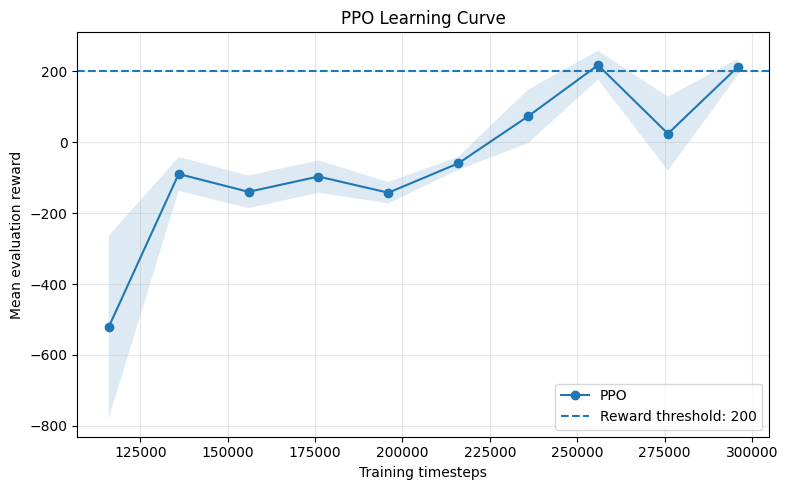

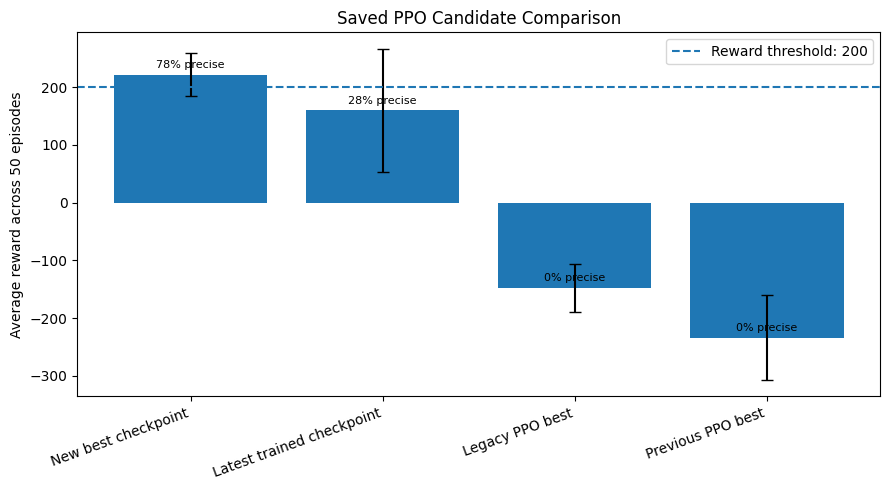


✅ Experiment finished.
✅ Original runs_v2 files were not intentionally modified.
✅ All new outputs are under runs_v3/ppo.


In [ ]:
# ============================================================
# LUNAR LANDER: PPO CONTINUATION + PRECISION EVALUATION
# Target: 300,000 total timesteps
# Does not intentionally restart training from scratch.
# ============================================================

import re
import time
from pathlib import Path

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import (
    EvalCallback,
    CheckpointCallback,
    CallbackList,
)

# ---------------- CONFIGURATION ----------------

ENV_ID = "LunarLander-v3"

TARGET_STEPS = 300_000
N_ENVS = 4
SEED = 0

EVAL_EVERY = 20_000
N_CURVE_EPISODES = 5
N_FINAL_EPISODES = 50
FINAL_SEED = 2000

# Keep existing experiments untouched.
SOURCE_DIR = Path("runs_v2/ppo")
LEGACY_DIR = Path("runs/ppo")

# New training outputs.
RUN_DIR = Path("runs_v3/ppo")
RUN_DIR.mkdir(parents=True, exist_ok=True)

PPO_KW = dict(
    n_steps=512,
    batch_size=64,
    n_epochs=4,
    gamma=0.999,
    gae_lambda=0.98,
    ent_coef=0.01,
    device="cpu",
    verbose=0,
)

# Custom precision criteria; these are not official Gymnasium metrics.
X_TOL = 0.15
VEL_TOL = 0.15
ANGLE_TOL = 0.15


# ---------------- CHECKPOINT DISCOVERY ----------------

def get_latest_checkpoint(folder):
    if not folder.exists():
        return None

    paths = list(folder.glob("checkpoint_model_*_steps.zip"))

    def step_number(path):
        match = re.search(r"_(\d+)_steps\.zip$", path.name)
        return int(match.group(1)) if match else -1

    paths = [p for p in paths if step_number(p) >= 0]
    return max(paths, key=step_number) if paths else None


def choose_resume_source():
    # Prefer the newest work in the new output folder.
    latest = get_latest_checkpoint(RUN_DIR)
    if latest is not None:
        return latest

    for folder in (RUN_DIR, SOURCE_DIR, LEGACY_DIR):
        for filename in ("best_model.zip", "final_selected_model.zip"):
            candidate = folder / filename
            if candidate.is_file():
                return candidate

        latest = get_latest_checkpoint(folder)
        if latest is not None:
            return latest

    # Optional baseline model from the original experiment.
    baseline = Path("ppo_lander_baseline.zip")
    if baseline.is_file():
        return baseline

    raise FileNotFoundError(
        "No existing PPO model was found. Restore your Google Drive "
        "backup or check runs_v2/ppo before training. "
        "Training was stopped to avoid silently starting from scratch."
    )


# ---------------- LANDING EVALUATION ----------------

def evaluate_model(model, episodes=50, seed=2000):
    env = gym.make(ENV_ID)

    rewards = []
    lengths = []
    precise_landings = []

    try:
        for ep in range(episodes):
            obs, _ = env.reset(seed=seed + ep)

            total_reward = 0.0
            length = 0
            terminated = False
            truncated = False

            while not (terminated or truncated):
                action, _ = model.predict(
                    obs,
                    deterministic=True,
                )
                action = int(np.asarray(action).item())

                obs, reward, terminated, truncated, _ = env.step(
                    action
                )

                total_reward += float(reward)
                length += 1

            both_legs = (
                float(obs[6]) > 0.5
                and float(obs[7]) > 0.5
            )

            centered = abs(float(obs[0])) <= X_TOL
            slow_horizontal = abs(float(obs[2])) <= VEL_TOL
            slow_vertical = abs(float(obs[3])) <= VEL_TOL
            upright = abs(float(obs[4])) <= ANGLE_TOL

            # Require a terminal (not time-limit truncated),
            # positive-reward landing with both legs touching.
            precise = (
                terminated
                and not truncated
                and total_reward >= 100
                and both_legs
                and centered
                and slow_horizontal
                and slow_vertical
                and upright
            )

            rewards.append(total_reward)
            lengths.append(length)
            precise_landings.append(precise)

    finally:
        env.close()

    return (
        np.asarray(rewards, dtype=float),
        np.asarray(lengths, dtype=int),
        np.asarray(precise_landings, dtype=bool),
    )


# ---------------- LOAD EXISTING MODEL ----------------

source_model = choose_resume_source()

print(f"Loading existing model: {source_model}")

train_env = make_vec_env(
    ENV_ID,
    n_envs=N_ENVS,
    seed=SEED,
)

eval_env = Monitor(gym.make(ENV_ID))
eval_env.reset(seed=9000)

model = PPO.load(
    str(source_model),
    env=train_env,
    device="cpu",
)

start_steps = int(model.num_timesteps)
remaining_steps = max(TARGET_STEPS - start_steps, 0)

print(f"Saved model timesteps: {start_steps:,}")
print(f"Target total timesteps: {TARGET_STEPS:,}")
print(f"Additional training timesteps: {remaining_steps:,}")


# ---------------- CALLBACKS ----------------

best_path = RUN_DIR / "best_model.zip"
evaluation_log = RUN_DIR / "evaluations.npz"

eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=str(RUN_DIR),
    log_path=str(RUN_DIR),
    eval_freq=max(EVAL_EVERY // N_ENVS, 1),
    n_eval_episodes=N_CURVE_EPISODES,
    deterministic=True,
    verbose=0,
)

# Restore evaluation history if this training run was interrupted.
if evaluation_log.is_file():
    try:
        with np.load(evaluation_log) as previous:
            old_results = previous["results"].copy()

            if old_results.size:
                eval_callback.best_mean_reward = max(
                    eval_callback.best_mean_reward,
                    float(old_results.mean(axis=1).max()),
                )

            # Preserve plotting history where compatible.
            if all(
                key in previous.files
                for key in ("timesteps", "results", "ep_lengths")
            ):
                eval_callback.evaluations_timesteps = (
                    previous["timesteps"].tolist()
                )
                eval_callback.evaluations_results = [
                    row.copy() for row in old_results
                ]
                eval_callback.evaluations_length = [
                    row.copy() for row in previous["ep_lengths"]
                ]

    except (OSError, KeyError, ValueError) as exc:
        print(f"Warning: evaluation history could not be restored: {exc}")

checkpoint_callback = CheckpointCallback(
    save_freq=max(EVAL_EVERY // N_ENVS, 1),
    save_path=str(RUN_DIR),
    name_prefix="checkpoint_model",
    verbose=0,
)

callbacks = CallbackList([
    eval_callback,
    checkpoint_callback,
])


# ---------------- CONTINUE TRAINING ----------------

training_start = time.time()

try:
    if remaining_steps > 0:
        model.learn(
            total_timesteps=remaining_steps,
            callback=callbacks,
            reset_num_timesteps=False,
        )
    else:
        print("Target already reached; skipping additional training.")

    # Save the latest model for future continuation.
    latest_name = (
        RUN_DIR / f"checkpoint_model_{model.num_timesteps}_steps"
    )
    model.save(str(latest_name))

finally:
    train_env.close()
    eval_env.close()

print(f"Training stage completed in {(time.time() - training_start) / 60:.1f} minutes.")
print(f"Current model timesteps: {model.num_timesteps:,}")


# ---------------- PREPARE CANDIDATES ----------------

# Ensure there is a usable model in the new run directory.
if not best_path.is_file():
    model.save(str(RUN_DIR / "best_model"))

candidate_specs = [
    ("New best checkpoint", best_path),
    ("Latest trained checkpoint", get_latest_checkpoint(RUN_DIR)),
    ("Previous PPO best", SOURCE_DIR / "best_model.zip"),
    ("Legacy PPO best", LEGACY_DIR / "best_model.zip"),
    ("Resume source", source_model),
    ("Previously selected model", RUN_DIR / "final_selected_model.zip"),
]

candidates = []
seen_paths = set()

for label, path in candidate_specs:
    if path is None or not Path(path).is_file():
        continue

    key = str(Path(path).resolve())

    if key not in seen_paths:
        seen_paths.add(key)
        candidates.append((label, Path(path)))

if not candidates:
    raise FileNotFoundError("No usable model candidates were found for evaluation.")


# ---------------- FAIR 50-EPISODE COMPARISON ----------------

comparison_rows = []
candidate_models = {}

for label, path in candidates:
    print(f"\nEvaluating: {label} ({path})")

    candidate_model = PPO.load(str(path), device="cpu")

    rewards, lengths, precise = evaluate_model(
        candidate_model,
        episodes=N_FINAL_EPISODES,
        seed=FINAL_SEED,
    )

    comparison_rows.append({
        "candidate": label,
        "path": str(path),
        "timesteps": int(candidate_model.num_timesteps),
        "avg_reward": round(float(rewards.mean()), 2),
        "std_reward": round(float(rewards.std()), 2),
        "avg_episode_length": round(float(lengths.mean()), 1),
        "episodes_reward_ge_200_pct": round(
            float((rewards >= 200).mean() * 100), 1
        ),
        "precise_landing_pct": round(
            float(precise.mean() * 100), 1
        ),
        "precise_landings": int(precise.sum()),
    })

    candidate_models[label] = candidate_model

results_df = pd.DataFrame(comparison_rows)

# Prioritise the custom precision metric; use reward as a tiebreaker.
results_df = results_df.sort_values(
    by=["precise_landing_pct", "avg_reward"],
    ascending=[False, False],
).reset_index(drop=True)

print("\nFINAL 50-EPISODE COMPARISON")
print(results_df.to_string(index=False))

results_df.to_csv(RUN_DIR / "candidate_comparison_50_episodes.csv", index=False)
results_df.to_json(
    RUN_DIR / "candidate_comparison_50_episodes.json",
    orient="records",
    indent=2,
)


# ---------------- SAVE SELECTED MODEL ----------------

winner_label = results_df.iloc[0]["candidate"]
winner_path = next(
    path for label, path in candidates if label == winner_label
)

winning_model = PPO.load(str(winner_path), device="cpu")
winning_model.save(str(RUN_DIR / "final_selected_model"))

print(f"\nSelected candidate: {winner_label}")
print(f"Source: {winner_path}")
print(f"Saved selected model: {RUN_DIR / 'final_selected_model.zip'}")

if results_df.iloc[0]["precise_landings"] == 0:
    print(
        "\nWARNING: No candidate met the defined precise-landing "
        "criteria in the 50 evaluation episodes. Do not claim that "
        "the lander can land precisely yet."
    )


# ---------------- GRAPH 1: LEARNING CURVE ----------------

if evaluation_log.is_file():
    with np.load(evaluation_log) as history:
        timesteps = history["timesteps"].copy()
        evaluation_rewards = history["results"].copy()

    if len(timesteps) > 0:
        means = evaluation_rewards.mean(axis=1)
        stds = evaluation_rewards.std(axis=1)

        plt.figure(figsize=(8, 5))
        plt.plot(timesteps, means, marker="o", label="PPO")
        plt.fill_between(
            timesteps,
            means - stds,
            means + stds,
            alpha=0.15,
        )
        plt.axhline(200, linestyle="--", label="Reward threshold: 200")
        plt.xlabel("Training timesteps")
        plt.ylabel("Mean evaluation reward")
        plt.title("PPO Learning Curve")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.savefig(RUN_DIR / "learning_curve_300k.png", dpi=150)
        plt.show()
    else:
        print("No evaluation curve points available yet.")


# ---------------- GRAPH 2: CANDIDATE RESULTS ----------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results_df["candidate"],
    results_df["avg_reward"],
    yerr=results_df["std_reward"],
    capsize=4,
)

plt.axhline(200, linestyle="--", label="Reward threshold: 200")
plt.ylabel("Average reward across 50 episodes")
plt.title("Saved PPO Candidate Comparison")
plt.xticks(rotation=20, ha="right")

for bar, pct in zip(bars, results_df["precise_landing_pct"]):
    plt.annotate(
        f"{pct:.0f}% precise",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

plt.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "candidate_comparison_300k.png", dpi=150)
plt.show()

print("\n✅ Experiment finished.")
print("✅ Original runs_v2 files were not intentionally modified.")
print("✅ All new outputs are under runs_v3/ppo.")

## 11. Final Landing Demonstration

Load the selected PPO model and record two deterministic-policy episodes in the LunarLander environment.

Use the videos to inspect the model's actual behaviour. Example successful episodes do not establish that the policy will land successfully in every episode.

In [ ]:
# ============================================================
# LUNAR LANDER: RECORD AND DISPLAY LANDING VIDEOS
# ============================================================

import time
from pathlib import Path

import numpy as np
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from stable_baselines3 import PPO
from IPython.display import Video, display

# ---------------- CONFIGURATION ----------------

ENV_ID = "LunarLander-v3"
MODEL = "ppo"
EPISODES = 2

# Correct paths based on your Colab folder structure.
CANDIDATE_PATHS = [
    Path("runs_v3/ppo/final_selected_model.zip"),
    Path("runs_v3/ppo/best_model.zip"),
]

# Fallback to the latest checkpoint if needed.
checkpoint_dir = Path("runs_v3/ppo")

if not any(p.is_file() for p in CANDIDATE_PATHS):
    checkpoints = list(
        checkpoint_dir.glob("checkpoint_model_*_steps.zip")
    )

    if checkpoints:
        import re

        def get_steps(path):
            match = re.search(
                r"checkpoint_model_(\d+)_steps\.zip$",
                path.name,
            )
            return int(match.group(1)) if match else -1

        latest = max(checkpoints, key=get_steps)

        if get_steps(latest) >= 0:
            CANDIDATE_PATHS.append(latest)

MODEL_PATH = next(
    (p for p in CANDIDATE_PATHS if p.is_file()),
    None,
)

if MODEL_PATH is None:
    raise FileNotFoundError(
        "No PPO model found. Check runs_v3/ppo/ "
        "and confirm that your model checkpoint exists."
    )

print(f"Loading model: {MODEL_PATH}")

model = PPO.load(str(MODEL_PATH), device="cpu")

# Use a unique folder to keep previous videos unchanged.
folder = Path("videos") / f"demo_{MODEL}_{int(time.time())}"
folder.mkdir(parents=True, exist_ok=True)

env = RecordVideo(
    gym.make(ENV_ID, render_mode="rgb_array"),
    video_folder=str(folder),
    episode_trigger=lambda episode: True,
    name_prefix=MODEL,
)

try:
    for ep in range(EPISODES):
        obs, _ = env.reset(seed=2000 + ep)

        total_reward = 0.0
        length = 0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action, _ = model.predict(
                obs,
                deterministic=True,
            )

            action = int(np.asarray(action).item())

            obs, reward, terminated, truncated, _ = env.step(
                action
            )

            total_reward += float(reward)
            length += 1

        print(
            f"Episode {ep + 1}: "
            f"reward={total_reward:.1f}, "
            f"length={length}, "
            f"terminated={terminated}, "
            f"truncated={truncated}"
        )

finally:
    env.close()

# Display only videos generated in this run.
video_files = sorted(folder.glob("*.mp4"))

if not video_files:
    print("No videos generated. Check the Colab output above.")
else:
    print(f"\nGenerated {len(video_files)} video(s):")

    for video_file in video_files:
        print(video_file)
        display(Video(str(video_file), embed=True, width=480))

Loading model: runs_v3/ppo/final_selected_model.zip


/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/videos/demo_ppo_1792163065 folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Episode 1: reward=225.6, length=494, terminated=True, truncated=False
Episode 2: reward=251.0, length=441, terminated=True, truncated=False

Generated 2 video(s):
videos/demo_ppo_1792163065/ppo-episode-0.mp4


videos/demo_ppo_1792163065/ppo-episode-1.mp4
